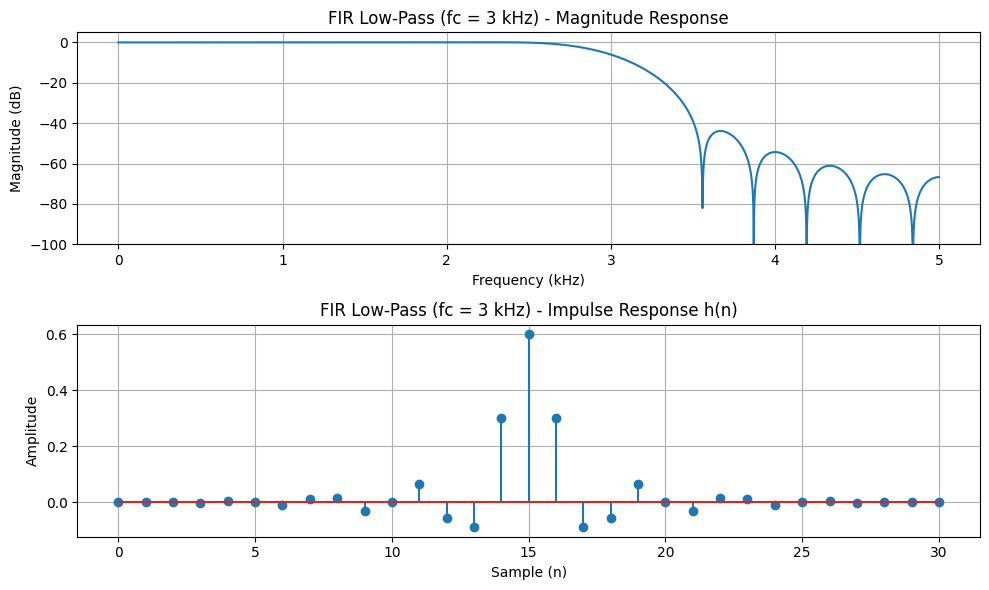

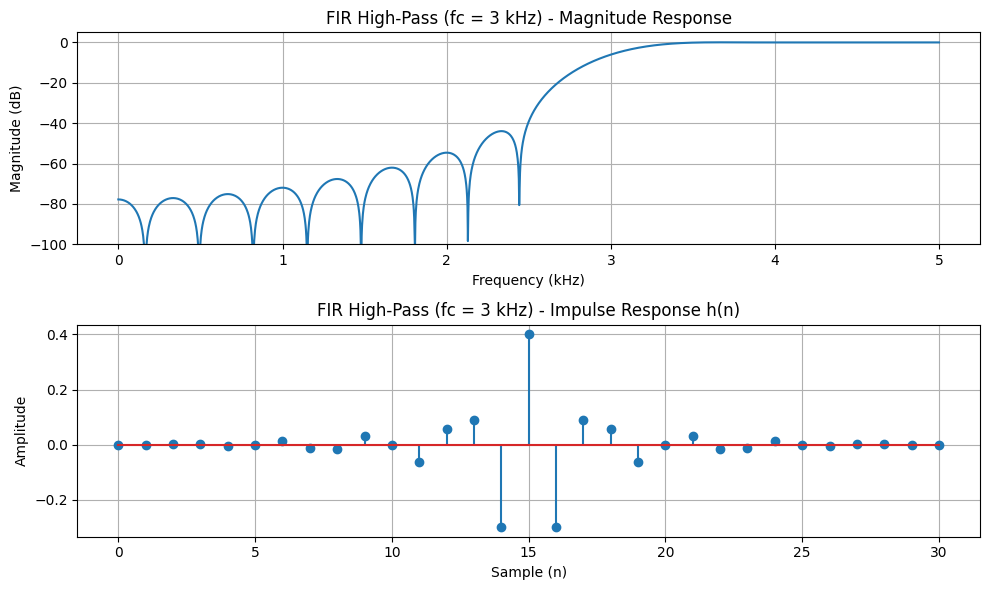

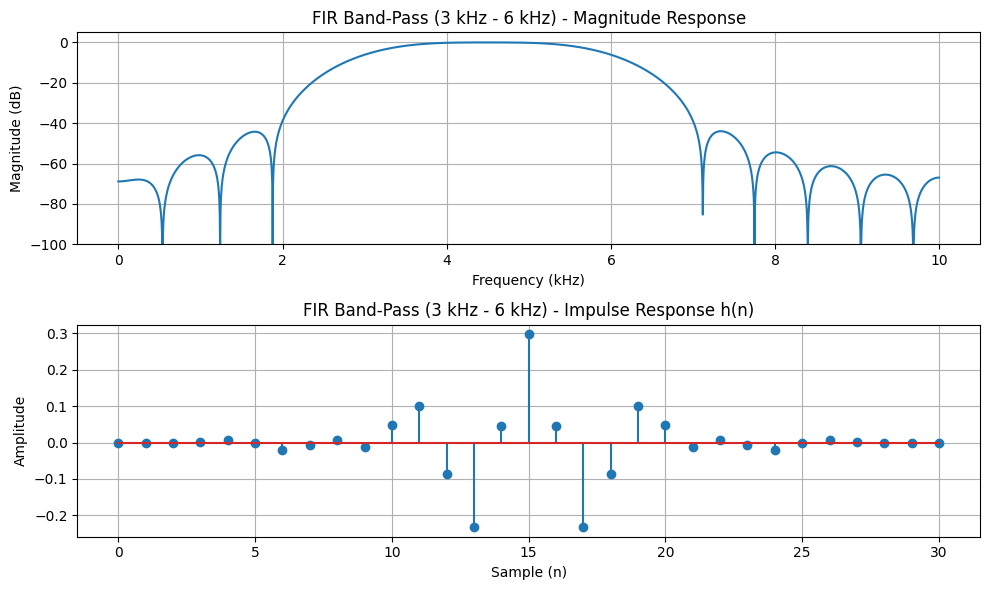

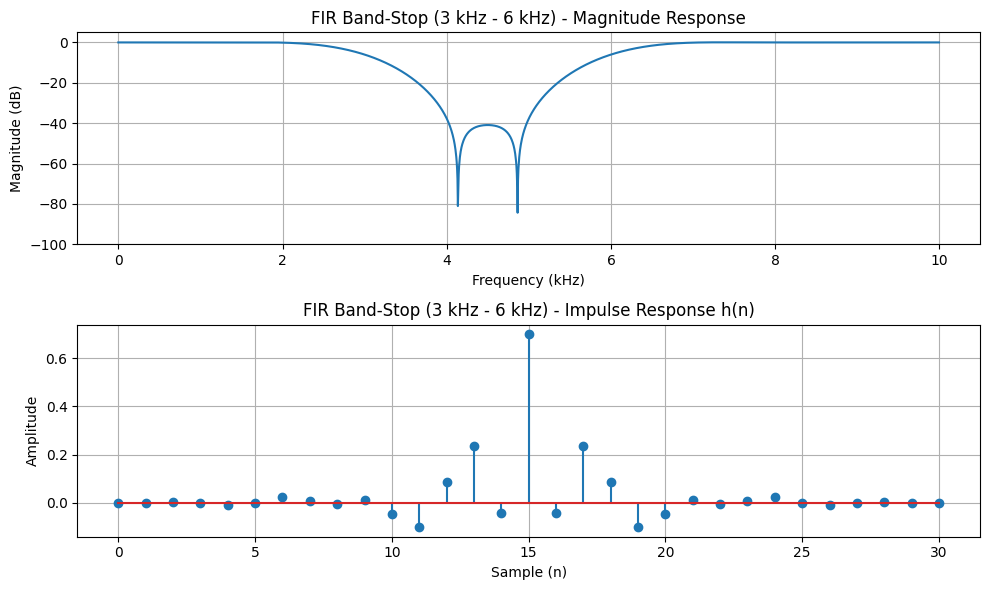

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

N = 31                      # number of filter taps

def design_and_plot(title, cutoff, ftype, Fs):
    # FIR design using Hann window
    b = firwin(numtaps=N, cutoff=cutoff, window='hann', pass_zero=ftype, fs=Fs)
    f, H = freqz(b, worN=2048, fs=Fs)
    magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-10))
    plt.figure(figsize=(10, 6))

    plt.subplot(2, 1, 1)
    plt.plot(f/1000, magnitude_db)
    plt.title(title + " - Magnitude Response")
    plt.xlabel("Frequency (kHz)")
    plt.ylabel("Magnitude (dB)")
    plt.ylim(-100, 5)
    plt.grid(True)
    plt.subplot(2, 1, 2)
    plt.stem(np.arange(N), b)
    plt.title(title + " - Impulse Response h(n)")
    plt.xlabel("Sample (n)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    return b

# 1. Low-pass filter, fc = 3 kHz, Fs = 10 kHz
b_lp = design_and_plot("FIR Low-Pass (fc = 3 kHz)", 3000, 'lowpass', 10000)
# 2. High-pass filter, fc = 3 kHz, Fs = 10 kHz
b_hp = design_and_plot("FIR High-Pass (fc = 3 kHz)", 3000, 'highpass', 10000)
# 3 & 4. Band filters (3 kHz - 6 kHz): 6 kHz > Nyquist (5 kHz) at Fs = 10 kHz,
# so Fs = 20 kHz is used for the band-pass and band-stop filters.
b_bp = design_and_plot("FIR Band-Pass (3 kHz - 6 kHz)", [3000, 6000], 'bandpass', 20000)
b_bs = design_and_plot("FIR Band-Stop (3 kHz - 6 kHz)", [3000, 6000], 'bandstop', 20000)